# Random Forest
- Random Forest is a powerful ensemble machine learning algorithm that is widely used for both classification and regression tasks. It's an ensemble method because it combines the predictions of multiple decision trees to make more accurate and robust predictions. Let's dive into the details of Random Forest, use the Iris dataset, and perform classification, including computing accuracy, generating a classification report, and visualizing the confusion matrix using Seaborn.

- Ensemble Learning: Ensemble learning involves combining the predictions of multiple individual models (learners) to produce a stronger, more accurate final prediction. Random Forest is one such ensemble method that combines multiple decision trees to make more reliable predictions.

# Important Points about Random Forest:

- **Ensemble Method:** Random Forest is an ensemble method that builds multiple decision trees and combines their predictions. This ensemble approach reduces overfitting and increases the model's accuracy and robustness.

- **Decision Trees:** Each tree in the Random Forest is a decision tree. Decision trees split the data into subsets based on feature values and make predictions based on majority class in each subset.

- **Bootstrapping:** Random Forest uses bootstrapping to create multiple subsets of the training data with replacement. Each tree is trained on a different subset of the data.

- **Random Feature Selection:** At each node of a decision tree, Random Forest randomly selects a subset of features to consider for splitting. This reduces the risk of individual trees overfitting to specific features.

- **Voting or Averaging:** For classification tasks, Random Forest combines the predictions of individual trees using majority voting. For regression tasks, it averages the predictions.


# Advantages of Random Forest:
- **Reduced Overfitting:** By building multiple trees with random features and bootstrapped datasets, Random Forest reduces the risk of overfitting that is often associated with a single, deep decision tree.
- **High Accuracy:** The ensemble nature of Random Forest leads to better generalization and improved accuracy compared to a single decision tree.
- **Robustness to Outliers:** Outliers have a diminished impact due to the random sampling during bootstrapping.
- **Feature Importance:** Random Forest provides a way to measure the importance of each feature in making predictions. Features that contribute more to reducing impurity are considered more important.


# Parameters and Tuning:
- **Number of Trees (n_estimators):** This parameter defines how many decision trees will be in the forest. A larger number usually improves performance but also increases computation time.
-	**Maximum Depth (max_depth):** Limits the depth of individual trees to prevent overfitting.
- **Minimum Samples to Split (min_samples_split) and Leaf (min_samples_leaf):** Set the minimum number of samples required to split a node or form a leaf, respectively.
-	**Number of Features to Consider (max_features):** Controls the number of features randomly considered for splitting at each node.



In [ ]:
# importing the libraries
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import warnings
warnings.filterwarnings("ignore")

In [ ]:
# Loading the Iris dataset from seaborn
iris = sns.load_dataset("iris")
X = iris.drop("species", axis=1)
y = iris[["species"]]

In [ ]:
# Splitting the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
# Creating a Random Forest Classifier
# row sampling
# n_estimators mean number of decision trees in Random Forest Model
# random_state produces the same results whenever you run the code.
rf_classifier = RandomForestClassifier(n_estimators=500, random_state=42)

# Training the classifier on the training data
rf_classifier.fit(X_train, y_train)

# Making predictions on the test data
y_pred = rf_classifier.predict(X_test)

# making prediciton on training data
y_pred_train = rf_classifier.predict(X_train)


In [ ]:
# Calculating accuracy
testing_accuracy = accuracy_score(y_test, y_pred)
traiing_accuracy = accuracy_score(y_train, y_pred_train)
print(f"Trainig Accuracy: {traiing_accuracy:.2f}")
print(f"Testing Accuracy: {testing_accuracy:.2f}")

Trainig Accuracy: 1.00
Testing Accuracy: 1.00


In [ ]:
# Generating a classification report
class_report = classification_report(y_test, y_pred, target_names=iris["species"].unique())
print("Classification Report:\n", class_report)

Classification Report:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



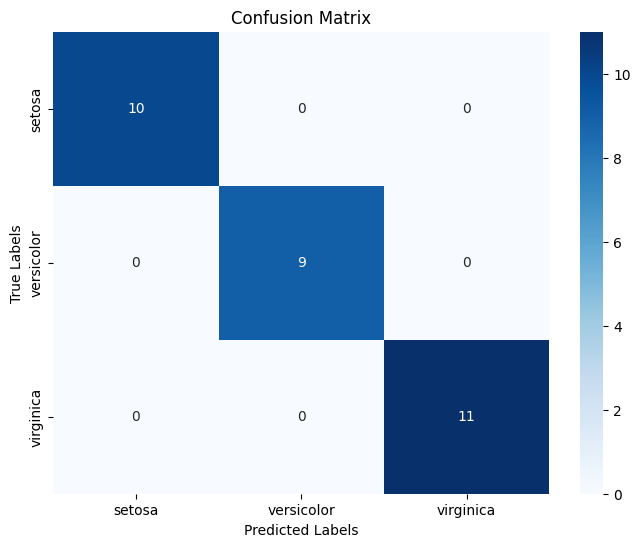

In [ ]:
# Generating a confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)

# Visualizing the confusion matrix using Seaborn
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=iris["species"].unique(), yticklabels=iris["species"].unique())
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
